In [42]:
# Min/max and error bars suggested by Claude (Anthropic). Main prompt: "Step 3 of the brief:
# time and speedup per worker count, median with min/max, node and job ID in the title."
# Adapted and corrected by me. Everything else is adapted from Turilli's scaling.ipynb.
# Time and efficiency plots and the title/subtitle idea from Claude (Anthropic); merged into chart() by me.
# Comparison table (Amdahl vs Karp-Flatt) suggested by Claude (Anthropic); I split it into steps and adapted it.
# Serial column (load + prepare + pool start + write); I added it to results() and chart().
# Compute-only speedup line and the 64-worker note on the charts suggested by Claude (Anthropic); I added them to results() and chart().

In [43]:
import matplotlib.pyplot as plt
import pandas as pd

In [44]:
def results(path):
    # One row per number of workers: median times, speedup and efficiency.

    runs = pd.read_csv(path)
    runs["serial"] = runs["pool_start_s"] + runs["load_s"] + runs["prepare_s"] + runs["write_s"]

    table = runs.groupby("workers")[["serial", "compute_wall_s", "total_s"]].median()
    table["speedup"] = table["total_s"].iloc[0] / table["total_s"]
    table["compute_speedup"] = table["compute_wall_s"].iloc[0] / table["compute_wall_s"]

    table["efficiency"] = table["speedup"] / table.index
    table["compute_efficiency"] = table["compute_speedup"] / table.index

    groups = runs.groupby("workers")["total_s"]
    table["total_min"] = groups.min()
    table["total_max"] = groups.max()
    table["speedup_min"] = table["total_s"].iloc[0] / table["total_max"]
    table["speedup_max"] = table["total_s"].iloc[0] / table["total_min"]

    groups2 = runs.groupby("workers")["compute_wall_s"]
    table["total_min_compute"] = groups2.min()
    table["total_max_compute"] = groups2.max()
    table["speedup_min_compute"] = table["compute_wall_s"].iloc[0] / table["total_max_compute"]
    table["speedup_max_compute"] = table["compute_wall_s"].iloc[0] / table["total_min_compute"]
    return table

def amdahl(s, n):
    if n > 32:
        return float("nan")
    return 1 / (s + (1 - s) / n)

def chart(table, color, plot):
    s = table["serial"].iloc[0] / table["total_s"].iloc[0]
    n = table.index
    if plot == 0:
        plt.plot(n, table["total_s"].iloc[0] / n, "--", color="#898781", label="ideal")

        errorbar = [table["total_s"] - table["total_min"], table["total_max"] - table["total_s"]]
        plt.errorbar(n, table["total_s"], yerr=errorbar, capsize=3, fmt="o-", color=color, label=f"total incl. pool start")

        errorbar1 = [table["compute_wall_s"] - table["total_min_compute"], table["total_max_compute"] - table["compute_wall_s"]]
        plt.errorbar(n, table["compute_wall_s"], yerr=errorbar1, capsize=3, fmt="o-", color="orange", label=f"compute only")

        plt.annotate("64 workers = 32 cores x 2 threads", xy=(64,2), xytext=(8, 10), arrowprops=dict(arrowstyle="->", color = "black"))
        plt.ylabel("total time")
        plt.suptitle("Time plot")
    elif plot == 1:
        plt.plot(n, n, "--", color="#898781", label="ideal")
        plt.plot(n, [amdahl(s, k) for k in n], color="#c3c2b7", linewidth=3, label=f"Amdahl, s = {s:.1%}")

        errorbar = [table["speedup"] - table["speedup_min"], table["speedup_max"] - table["speedup"]]
        plt.errorbar(n, table["speedup"], yerr=errorbar, capsize=3, fmt="o-", color=color, label=f"total incl. pool start")
        
        errorbar1 = [table["compute_speedup"] - table["speedup_min_compute"], table["speedup_max_compute"] - table["compute_speedup"]]
        plt.errorbar(n, table["compute_speedup"], yerr=errorbar1, capsize=3, fmt="o-", color="orange", label=f"compute only")

        plt.annotate("64 workers = 32 cores x 2 threads", xy=(64,36.5), xytext=(4, 40), arrowprops=dict(arrowstyle="->", color = "black"))
        plt.ylabel("speedup")
        plt.suptitle("Speedup plot")
    else:
        plt.plot(n, table["efficiency"], "o-", color= color, label = "total incl. pool start")
        plt.plot(n, table["compute_efficiency"], "o-", color= "orange", label = "compute only")

        plt.axhline(1, ls="--", color="#898781", label="ideal")
        plt.ylabel("efficiency")
        plt.suptitle("Efficiency plot")
    plt.xscale("log", base=2)
    plt.xticks(n, n)
    plt.xlabel("workers")
    
    plt.title(f"node {runs['node'].iloc[0]} & job {runs['job_id'].iloc[0]}")
    plt.legend()

def serial_fraction(table):
    n = table.index[1:]
    S = table["speedup"].iloc[1:]
    return ((1 / S - 1 / n) / (1 - 1 / n)).round(3)


In [45]:
compute = results("../results/scaling-30974.csv")
runs = pd.read_csv("../results/scaling-30974.csv")

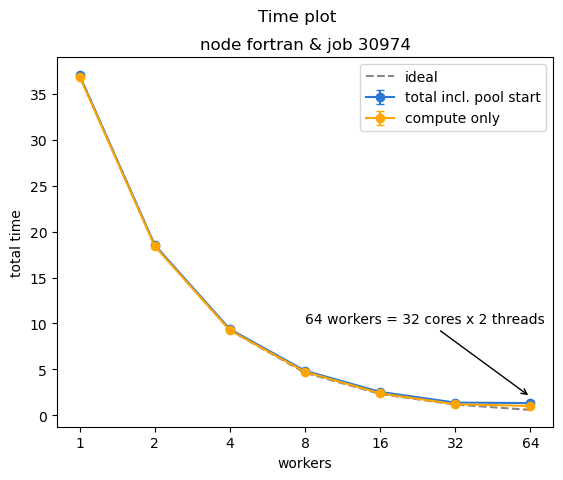

In [46]:
chart(compute, "#2a78d6", 0)
plt.savefig("time.png")

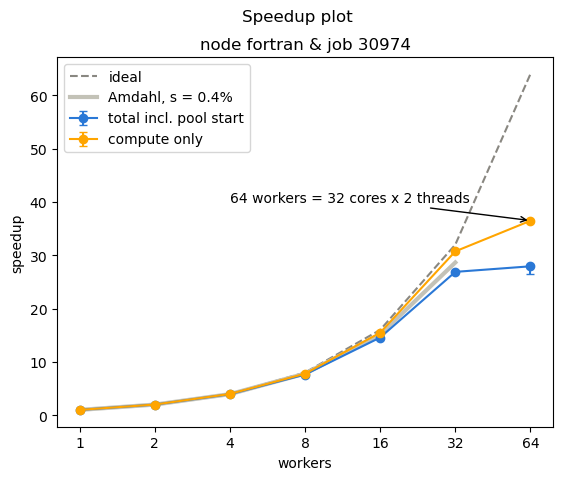

In [47]:
chart(compute, "#2a78d6", 1)
plt.savefig("strong.png")

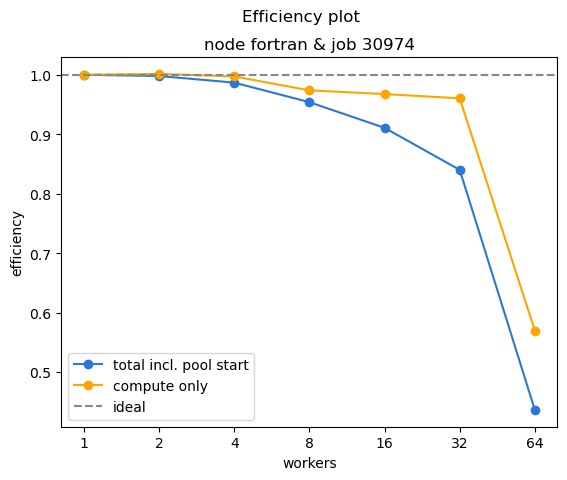

In [48]:
chart(compute, "#2a78d6", 2)
plt.savefig("efficiency.png")

In [49]:
s = compute["serial"].iloc[0] / compute["total_s"].iloc[0]
n = compute.index

# Serial fraction Amdahl
am = [amdahl(s, k) for k in n]

# Serial fraction Karp-Flatt
sf = serial_fraction(compute)

comparison = pd.DataFrame({
    "measured speedup" : compute["speedup"],
    "measured compute speedup" : compute["compute_speedup"],
    "Amdahl" : am,
    "Karp-Flatt" : sf
})

comparison.reset_index(inplace=True)
comparison.round(3)

,workers,measured speedup,measured compute speedup,Amdahl,Karp-Flatt
0,1,1.000,1.000,1.000,NaN
1,2,1.996,2.003,1.992,0.002
2,4,3.947,3.989,3.955,0.004
3,8,7.631,7.790,7.794,0.007
4,16,14.572,15.481,15.141,0.007
5,32,26.883,30.731,28.643,0.006
6,64,27.926,36.465,NaN,0.021
